# 02. Back-end database: menyimpan dan membaca riwayat EKG

**Tujuan.** Membandingkan empat konfigurasi penyimpanan paket EKG 1 detik (250 sampel) di PostgreSQL 16:
1. PostgreSQL biasa (query agregat langsung ke tabel mentah),
2. PostgreSQL + materialized view (pembanding yang adil untuk ringkasan),
3. TimescaleDB hypertable (query agregat langsung ke tabel mentah),
4. TimescaleDB + continuous aggregate.

Versi 1 membandingkan konfigurasi 1, 3, dan 4 saja, dan hanya mengukur kecepatan query. Konfigurasi 2 ditambahkan, dan sisi biaya ikut diukur: kecepatan insert, biaya refresh ringkasan, ukuran penyimpanan, dan rasio kompresi.

**Data.** Sinyal MIT-BIH (44 rekaman tanpa alat pacu, notebook 00) dipotong per 1 detik (250 sampel, dalam hitungan ADC 12 bit dengan asumsi 1 mV = 400 hitungan, TODO: cocokkan dengan kalibrasi AD8232). Potongan disusun berurutan menjadi satu siklus sekitar 22 jam, lalu **diputar ulang** tanpa perubahan untuk mengisi 30 hari. Tiap pasien mulai dari titik berbeda dalam siklus. Pasien 1 (yang di-query) punya 30 hari. 9 pasien latar belakang punya 3 hari terakhir saja, supaya indeks dan partisi tidak hanya berisi satu perangkat.

**Efek pengulangan data.** Kompresi TimescaleDB bekerja per batch baris berurutan (sekitar 1.000 baris, sekitar 17 menit data), dan siklus ulang 22 jam jauh lebih panjang dari batch itu, jadi pengulangan seharusnya tidak membuat rasio kompresi tampak lebih baik. Ini belum dibuktikan. Sebagai pengecekan, rasio dilaporkan per chunk: chunk hari pertama berisi data unik, chunk berikutnya berisi data hasil putar ulang. TODO: verifikasi sumber tentang cara kerja batching kompresi.

**Cara ukur.**
- Pengaturan PostgreSQL: `shared_buffers=1GB`, `work_mem=64MB`, `jit=off` (sama dengan versi 1), dalam Docker Desktop (VM Linux di macOS). Docker di Mac punya overhead I/O, jadi angka mutlak tidak bisa dibandingkan dengan server Linux langsung.
- Waktu query: pemanasan 2 kali dibuang, lalu minimal 7 ulangan. Query riwayat memakai rentang yang sama berulang (cache hangat, bukan cache dingin; cache dingin tidak diukur). Query zoom 10 detik memakai 30 waktu acak (seed tetap), jadi tidak selalu kena cache.
- Insert: (a) bulk `COPY` dengan indeks sudah ada, (b) satu baris per `INSERT` (satu koneksi, autocommit), (c) 200 baris per perintah (satu paket per perangkat per detik untuk 200 pasien).
- Refresh: setelah ditambah 1 jam data baru, waktu `REFRESH MATERIALIZED VIEW` (hitung ulang seluruh tabel), `REFRESH ... CONCURRENTLY`, dan `refresh_continuous_aggregate` hanya pada rentang baru. Diulang 5 kali.
- Ukuran: sebelum dan sesudah kompresi (chunk yang lebih tua dari 1 hari dikompresi, dengan `segmentby=device_id`, `orderby=ts`).

**Keterbatasan.** Satu mesin, satu kontainer, satu pasien yang di-query, cache hangat, data MIT-BIH yang diputar ulang, tanpa beban baca dan tulis bersamaan.

In [1]:
import sys, json, pathlib, subprocess, time, random, io
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, psycopg2, matplotlib.pyplot as plt
from psycopg2.extras import execute_values
from bench import env, plotstyle, stats, mitdb
from bench.plotstyle import ST
random.seed(0); np.random.seed(0)
QUICK = False
DAYS_MAIN, DAYS_BG, N_BG = (3, 1, 9) if QUICK else (30, 3, 9)
REPS = 7
CONN = dict(host="localhost", port=5440, user="postgres", password="postgres")
START = np.datetime64("2026-09-01T00:00:00"); END = START + np.timedelta64(DAYS_MAIN, "D")
ENDS = str(END).replace("T", " ") + "+00"
def conn(db="postgres", auto=True):
    c = psycopg2.connect(dbname=db, **CONN); c.autocommit = auto; return c

## 1. Kontainer dan lingkungan

In [2]:
subprocess.run(["docker", "compose", "-f", str(ROOT/"docker-compose.yml"), "up", "-d"], check=True, capture_output=True)
for _ in range(60):
    try: conn().close(); break
    except Exception: time.sleep(1)
c = conn(); cur = c.cursor()
for db in ("plain", "ts"):
    cur.execute(f"drop database if exists {db} with (force)"); cur.execute(f"create database {db}")
c.close(); c = conn("ts"); c.cursor().execute("create extension if not exists timescaledb"); c.close()
c = conn("ts"); cur = c.cursor(); cur.execute("select version()"); pgv = cur.fetchone()[0]
cur.execute("select extversion from pg_extension where extname='timescaledb'"); tsv = cur.fetchone()[0]
cur.execute("select name, setting from pg_settings where name in ('shared_buffers','work_mem','jit','max_wal_size')"); st = dict(cur.fetchall())
dk = subprocess.run(["docker", "info", "--format", "{{.MemTotal}} {{.NCPU}} {{.ServerVersion}}"], capture_output=True, text=True).stdout.split()
img = subprocess.run(["docker", "inspect", "ekg_bench_db", "--format", "{{.Image}}"], capture_output=True, text=True).stdout.strip()
e = env.info(["psycopg2-binary"]); e.update(postgres=pgv.split(",")[0], timescaledb=tsv, pg_settings=st, docker_mem_gb=round(int(dk[0])/2**30, 1),
                                          docker_ncpu=dk[1], docker_version=dk[2], image_id=img, quick=QUICK, days_main=DAYS_MAIN, days_bg=DAYS_BG)
json.dump(e, open(ROOT/"results/env_02.json", "w"), indent=1); pd.Series(e, name="nilai").astype(str).to_frame()

,nilai
cpu,Apple M2
inti_fisik,8
inti_logis,8
ram_gb,16.0
os,macOS-27.0.1-arm64-arm-64bit
python,3.11.15
psycopg2-binary,2.9.13
postgres,PostgreSQL 16.15 on aarch64-unknown-linux-musl
timescaledb,2.31.0
pg_settings,"{'jit': 'off', 'max_wal_size': '8192', 'shared..."


## 2. Siapkan data: potongan 1 detik dari MIT-BIH

Satu siklus berisi semua rekaman (selain alat pacu), dipotong per 250 sampel. Penghitungan `pmin`, `pmax`, `pmean` per paket mengikuti skema versi 1.

In [3]:
z = np.load(ROOT/"data/processed/mitdb_250hz.npz")
ids = sorted(mitdb.DS1 + mitdb.DS2); pk = []
for r in ids:
    x = np.clip(2048 + z[f"x_{r}"] * 400, 0, 4095).astype(np.int16); n = len(x) // 250; pk.append(x[:n*250].reshape(n, 250))
P = np.concatenate(pk); CYCLE = len(P)
TXT = ["{" + ",".join(map(str, row)) + "}" for row in P]; PMIN, PMAX, PMEAN = P.min(1), P.max(1), P.mean(1)
print(f"siklus: {CYCLE} paket = {CYCLE/3600:.1f} jam; baris yang akan dimuat: pasien 1 = {DAYS_MAIN*86400}, latar = {N_BG} x {DAYS_BG*86400}")

def rows_text(dev, t0, n, off, seq0=0):
    idx = (off + np.arange(n)) % CYCLE
    ts = np.datetime_as_string(t0 + np.arange(n).astype("timedelta64[s]"), unit="s")
    return "".join(f"{dev}\t{seq0+i}\t{ts[i]}+00\t{TXT[j]}\t{PMIN[j]}\t{PMAX[j]}\t{PMEAN[j]:.2f}\n" for i, j in enumerate(idx))

def copy_rows(cur, dev, t0, n, off, batch=100_000):
    for s in range(0, n, batch):
        k = min(batch, n - s); buf = io.StringIO(rows_text(dev, t0 + np.timedelta64(s, "s"), k, off + s, s)); cur.copy_expert("copy packets from stdin", buf)

siklus: 79420 paket = 22.1 jam; baris yang akan dimuat: pasien 1 = 2592000, latar = 9 x 259200


## 3. Buat tabel dan isi (bulk COPY, indeks sudah ada)

In [4]:
DDL = "create table packets(device_id int, seq bigint, ts timestamptz not null, samples int2[], pmin int2, pmax int2, pmean real)"
load = []
for db in ("plain", "ts"):
    c = conn(db); cur = c.cursor(); cur.execute(DDL)
    if db == "ts": cur.execute("select create_hypertable('packets', by_range('ts', interval '1 day'))")
    cur.execute("create unique index on packets(device_id, ts)")
    t = time.perf_counter(); n = 0
    copy_rows(cur, 1, START, DAYS_MAIN * 86400, 0); n += DAYS_MAIN * 86400
    for d in range(2, 2 + N_BG):
        copy_rows(cur, d, END - np.timedelta64(DAYS_BG, "D"), DAYS_BG * 86400, d * 7919); n += DAYS_BG * 86400
    el = time.perf_counter() - t; cur.execute("vacuum analyze packets")
    load.append({"db": db, "baris": n, "detik": el, "baris_per_detik": n / el}); print(db, f"{n} baris, {el:.0f} s, {n/el:,.0f} baris/s", flush=True)
pd.DataFrame(load).to_csv(ROOT/"results/02_bulk_insert.csv", index=False); pd.DataFrame(load).round(1)

plain 4924800 baris, 88 s, 56,081 baris/s


ts 4924800 baris, 111 s, 44,473 baris/s


,db,baris,detik,baris_per_detik
0,plain,4924800,87.8,56080.7
1,ts,4924800,110.7,44473.4


## 4. Kecepatan insert mode real-time

Satu baris per `INSERT` dan 200 baris per perintah, di tabel yang sudah berisi data penuh, dengan indeks. Baris uji ditambahkan setelah rentang query lalu dihapus.

In [5]:
def ins_test(db):
    c = conn(db); cur = c.cursor(); out = {}
    t0 = END + np.timedelta64(1, "D"); tt = lambda i: str(t0 + np.timedelta64(i, "s")).replace("T", " ") + "+00"
    lat = []
    for i in range(3000):
        j = i % CYCLE; a = time.perf_counter()
        cur.execute("insert into packets values (1,%s,%s,%s,%s,%s,%s)", (10**9 + i, tt(i), TXT[j], int(PMIN[j]), int(PMAX[j]), float(PMEAN[j]))); lat.append((time.perf_counter() - a) * 1000)
    out["1_baris_per_insert_rows_s"] = 1000 / np.mean(lat); out["1_baris_p99_ms"] = np.percentile(lat, 99)
    lat = []
    for b in range(30):
        rows = [(100 + d, 10**9 + b, tt(10000 + b), TXT[d], int(PMIN[d]), int(PMAX[d]), float(PMEAN[d])) for d in range(200)]
        a = time.perf_counter(); execute_values(cur, "insert into packets values %s", rows); lat.append((time.perf_counter() - a) * 1000)
    out["200_baris_per_perintah_rows_s"] = 200 * 1000 / np.mean(lat); out["200_baris_p99_ms"] = np.percentile(lat, 99)
    cur.execute("delete from packets where seq >= 1000000000")
    cur.execute("vacuum packets"); c.close(); return {"db": db, **out}
ins = pd.DataFrame([ins_test("plain"), ins_test("ts")]); ins.to_csv(ROOT/"results/02_insert_realtime.csv", index=False); ins.round(1).T

,0,1
db,plain,ts
1_baris_per_insert_rows_s,2942.7,2381.8
1_baris_p99_ms,0.4,0.7
200_baris_per_perintah_rows_s,17754.6,14430.2
200_baris_p99_ms,13.9,28.5


## 5. Ringkasan per menit dan biaya refresh

Ringkasan: min, max, rata-rata per menit per perangkat. Dibuat awal dari seluruh data, lalu diukur biaya refresh setelah 1 jam data baru ditambahkan (5 kali). `REFRESH MATERIALIZED VIEW` menghitung ulang seluruh tabel, sedangkan `refresh_continuous_aggregate` hanya memproses rentang yang diminta. Perbedaan itu memang sifat kedua fitur, dan biayanya diukur di sini pada tabel 30 hari.

In [6]:
cp = conn("plain"); cu = cp.cursor(); ct = conn("ts"); cut = ct.cursor()
t = time.perf_counter()
cu.execute("create materialized view hist_1m as select device_id, date_trunc('minute', ts) b, min(pmin) mn, max(pmax) mx, avg(pmean) av from packets group by 1,2 with no data")
cu.execute("create unique index on hist_1m(device_id, b)"); cu.execute("refresh materialized view hist_1m"); build_mv = time.perf_counter() - t
t = time.perf_counter()
cut.execute("create materialized view hist_1m with (timescaledb.continuous) as select device_id, time_bucket('1 minute', ts) b, min(pmin) mn, max(pmax) mx, avg(pmean) av from packets group by 1,2 with no data")
cut.execute("alter materialized view hist_1m set (timescaledb.materialized_only = true)")
cut.execute("call refresh_continuous_aggregate('hist_1m', null, null)"); build_ca = time.perf_counter() - t
cu.execute("vacuum analyze hist_1m"); print(f"pembuatan awal: matview {build_mv:.1f} s, continuous aggregate {build_ca:.1f} s")
def add_hour(cur, k):
    t0 = END + np.timedelta64(k, "h"); cur.copy_expert("copy packets from stdin", io.StringIO(rows_text(1, t0, 3600, 5000 + k * 3600, 2_000_000 + k * 3600)))
def win(k): return tuple(str(END + np.timedelta64(j, "h")).replace("T", " ") + "+00" for j in (k, k + 1))
rows = []
for rep in range(5):
    k = 2 * rep; add_hour(cu, k); add_hour(cut, k)
    a = time.perf_counter(); cu.execute("refresh materialized view hist_1m"); r1 = time.perf_counter() - a
    a = time.perf_counter(); cut.execute("call refresh_continuous_aggregate('hist_1m', %s, %s)", win(k)); r3 = time.perf_counter() - a
    add_hour(cu, k + 1); add_hour(cut, k + 1)
    a = time.perf_counter(); cu.execute("refresh materialized view concurrently hist_1m"); r2 = time.perf_counter() - a
    cut.execute("call refresh_continuous_aggregate('hist_1m', %s, %s)", win(k + 1))  # agar cagg tetap sinkron, tidak diukur
    rows.append({"rep": rep, "matview_penuh_s": r1, "matview_concurrently_s": r2, "cagg_inkremental_s": r3})
rf = pd.DataFrame(rows); rf.to_csv(ROOT/"results/02_refresh.csv", index=False)
pd.DataFrame({"matview_build_awal_s": [build_mv], "cagg_build_awal_s": [build_ca]}).to_csv(ROOT/"results/02_build_awal.csv", index=False)
rf.round(3)

pembuatan awal: matview 4.5 s, continuous aggregate 25.6 s


,rep,matview_penuh_s,matview_concurrently_s,cagg_inkremental_s
0,0,4.144,2.984,0.027
1,1,2.039,2.027,0.009
2,2,1.456,1.972,0.009
3,3,1.888,1.876,0.009
4,4,1.418,1.854,0.009


## 6. Waktu query tanpa kompresi

- **Riwayat**: min/max/rata-rata per menit untuk 1 jam sampai 30 hari terakhir pasien 1 (sebelum jam tambahan di bagian 5).
- **Zoom**: 10 paket mentah (10 detik) di waktu acak pasien 1.

In [7]:
RNG = [("1 jam", "1 hour"), ("6 jam", "6 hours"), ("1 hari", "1 day"), ("7 hari", "7 days"), ("30 hari", f"{DAYS_MAIN} days")]
E = f"timestamptz '{ENDS}'"
RAW = "select date_trunc('minute', ts) b, min(pmin), max(pmax), avg(pmean) from packets where device_id=1 and ts >= {e} - interval '{r}' and ts < {e} group by 1 order by 1"
AGG = "select b, mn, mx, av from hist_1m where device_id=1 and b >= {e} - interval '{r}' and b < {e} order by 1"
CFG = [("PostgreSQL biasa", "plain", RAW), ("PostgreSQL + materialized view", "plain", AGG), ("TimescaleDB hypertable", "ts", RAW),
       ("TimescaleDB + continuous aggregate", "ts", AGG)]
def timeit(cur, sql, reps=REPS, warm=2):
    ts = []
    for k in range(reps + warm):
        a = time.perf_counter(); cur.execute(sql); rows = cur.fetchall(); ts.append((time.perf_counter() - a) * 1000)
    return ts[warm:], len(rows)
conns = {"plain": cu, "ts": cut}; hist = []
def run_hist(cfgs, kond):
    for name, db, q in cfgs:
        for lab, r in RNG:
            ts, n = timeit(conns[db], q.format(e=E, r=r)); hist.append({"konfigurasi": name, "kondisi": kond, "rentang": lab, "n_baris": n, **{f"t{i}": v for i, v in enumerate(ts)}})
        print(name, kond, "selesai", flush=True)
run_hist(CFG, "tanpa kompresi")

PostgreSQL biasa tanpa kompresi selesai


PostgreSQL + materialized view tanpa kompresi selesai


TimescaleDB hypertable tanpa kompresi selesai


TimescaleDB + continuous aggregate tanpa kompresi selesai


In [8]:
# zoom 10 detik: 30 waktu acak, tiap waktu diukur satu kali (satu pemanasan di waktu lain)
rg = np.random.default_rng(1); span = DAYS_MAIN * 86400 - 20; offs = rg.integers(0, span, 30)
def zoom_sql(o): return f"select ts, samples from packets where device_id=1 and ts >= timestamptz '2026-09-01 00:00:00+00' + interval '{o} seconds' and ts < timestamptz '2026-09-01 00:00:00+00' + interval '{o+10} seconds' order by ts"
zoom = []
def zrun(name, db, kond):
    cur = conns[db]; cur.execute(zoom_sql(int(offs[0]))); cur.fetchall()
    for o in offs:
        a = time.perf_counter(); cur.execute(zoom_sql(int(o))); n = len(cur.fetchall()); zoom.append({"konfigurasi": name, "kondisi": kond, "ms": (time.perf_counter() - a) * 1000, "n_baris": n})
zrun("PostgreSQL biasa", "plain", "tanpa kompresi"); zrun("TimescaleDB hypertable", "ts", "tanpa kompresi")
pd.DataFrame(zoom).groupby(["konfigurasi", "kondisi"]).ms.median().round(2)

konfigurasi             kondisi       
PostgreSQL biasa        tanpa kompresi    0.67
TimescaleDB hypertable  tanpa kompresi    0.73
Name: ms, dtype: float64

## 7. Ukuran penyimpanan, kompresi, dan query pada data terkompresi

Chunk yang lebih tua dari 1 hari dikompresi (`segmentby=device_id`, `orderby=ts`). Rasio dilaporkan total dan per chunk (chunk pertama berisi data unik, sisanya data putar ulang). Query riwayat dan zoom diulang pada data terkompresi, karena kompresi punya biaya baca.

In [9]:
def sizes(cur, ts):
    d = {}
    if ts:
        cur.execute("select hypertable_size('packets')"); d["tabel_mentah"] = cur.fetchone()[0]
        cur.execute("select hypertable_size(format('%I.%I', materialization_hypertable_schema, materialization_hypertable_name)) from timescaledb_information.continuous_aggregates where view_name='hist_1m'")
        d["ringkasan"] = cur.fetchone()[0]
    else:
        cur.execute("select pg_total_relation_size('packets')"); d["tabel_mentah"] = cur.fetchone()[0]
        cur.execute("select pg_total_relation_size('hist_1m')"); d["ringkasan"] = cur.fetchone()[0]
    return d
sz = [{"konfigurasi": "PostgreSQL biasa + matview", "fase": "tanpa kompresi", **sizes(cu, False)},
      {"konfigurasi": "TimescaleDB + cagg", "fase": "tanpa kompresi", **sizes(cut, True)}]
cut.execute("alter table packets set (timescaledb.compress, timescaledb.compress_segmentby='device_id', timescaledb.compress_orderby='ts')")
t = time.perf_counter()
cut.execute("select compress_chunk(c, if_not_compressed => true) from show_chunks('packets', older_than => %s::timestamptz - interval '1 day') c", (ENDS,)); cut.fetchall()
t_comp = time.perf_counter() - t; cut.execute("vacuum analyze packets")
sz.append({"konfigurasi": "TimescaleDB + cagg", "fase": "terkompresi", **sizes(cut, True)})
SZ = pd.DataFrame(sz); SZ["tabel_mentah_mb"] = SZ.tabel_mentah / 2**20; SZ["ringkasan_mb"] = SZ.ringkasan / 2**20; SZ["total_mb"] = SZ.tabel_mentah_mb + SZ.ringkasan_mb
SZ.to_csv(ROOT/"results/02_ukuran.csv", index=False); pd.DataFrame({"waktu_kompresi_s": [t_comp]}).to_csv(ROOT/"results/02_waktu_kompresi.csv", index=False)
cut.execute("select chunk_name, before_compression_total_bytes, after_compression_total_bytes from chunk_compression_stats('packets') where after_compression_total_bytes is not null order by chunk_name")
cs = pd.DataFrame(cut.fetchall(), columns=["chunk", "sebelum", "sesudah"]); cs["rasio"] = cs.sebelum / cs.sesudah; cs.to_csv(ROOT/"results/02_kompresi_per_chunk.csv", index=False)
print(f"waktu kompresi: {t_comp:.1f} s; chunk terkompresi: {len(cs)}; rasio total: {cs.sebelum.sum()/cs.sesudah.sum():.2f}")
print(f"rasio chunk pertama (data unik): {cs.rasio.iloc[0]:.2f}; median chunk lain (putar ulang): {cs.rasio.iloc[1:].median():.2f}")
SZ[["konfigurasi", "fase", "tabel_mentah_mb", "ringkasan_mb", "total_mb"]].round(1)

waktu kompresi: 25.1 s; chunk terkompresi: 29; rasio total: 1.78
rasio chunk pertama (data unik): 1.82; median chunk lain (putar ulang): 1.81


,konfigurasi,fase,tabel_mentah_mb,ringkasan_mb,total_mb
0,PostgreSQL biasa + matview,tanpa kompresi,3137.4,7.5,3145.0
1,TimescaleDB + cagg,tanpa kompresi,3255.7,9.5,3265.3
2,TimescaleDB + cagg,terkompresi,2081.3,9.5,2090.9


In [10]:
run_hist([c for c in CFG if c[1] == "ts"], "terkompresi"); zrun("TimescaleDB hypertable", "ts", "terkompresi")
pd.DataFrame(hist).to_csv(ROOT/"results/02_query_riwayat_raw.csv", index=False)
pd.DataFrame(zoom).to_csv(ROOT/"results/02_query_zoom_raw.csv", index=False)

TimescaleDB hypertable terkompresi selesai


TimescaleDB + continuous aggregate terkompresi selesai


## 8. Ringkasan dan grafik

In [11]:
H = pd.read_csv(ROOT/"results/02_query_riwayat_raw.csv"); tc = [c for c in H.columns if c.startswith("t") and c[1:].isdigit()]
rows = []
for _, r in H.iterrows():
    a = stats.summ(r[tc].values.astype(float)); rows.append({"konfigurasi": r.konfigurasi, "kondisi": r.kondisi, "rentang": r.rentang, "median_ms": a["median"],
        "iqr": f'{a["q1"]:.1f}-{a["q3"]:.1f}', "ci95": f'{a["ci_lo"]:.1f}-{a["ci_hi"]:.1f}', "n_baris": r.n_baris})
HS = pd.DataFrame(rows); HS.to_csv(ROOT/"results/02_query_riwayat_ringkasan.csv", index=False)
HS[HS.kondisi == "tanpa kompresi"].pivot(index="rentang", columns="konfigurasi", values="median_ms").loc[[l for l, _ in RNG]].round(2)

konfigurasi,PostgreSQL + materialized view,PostgreSQL biasa,TimescaleDB + continuous aggregate,TimescaleDB hypertable
rentang,,,,
1 jam,0.42,1.42,0.47,1.23
6 jam,0.67,7.08,0.88,5.94
1 hari,1.80,36.64,2.63,31.44
7 hari,11.31,263.60,12.15,204.56
30 hari,51.93,1667.38,36.10,1345.17


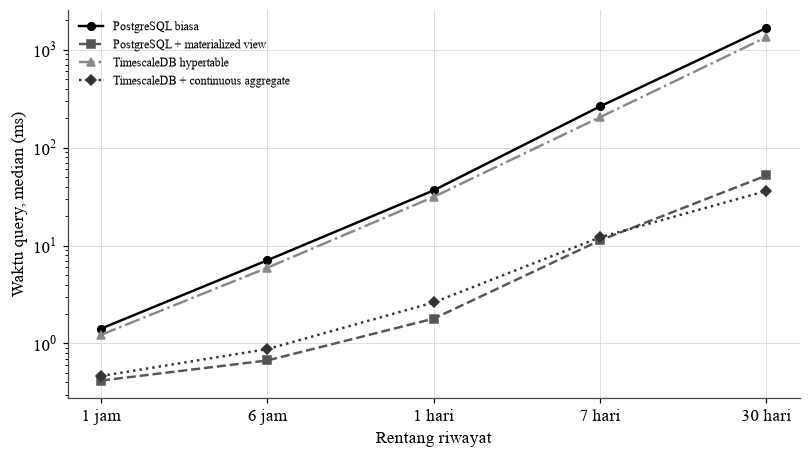

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 4.3))
for (name, st) in zip([c[0] for c in CFG], ST):
    s = HS[(HS.konfigurasi == name) & (HS.kondisi == "tanpa kompresi")].set_index("rentang").loc[[l for l, _ in RNG]]
    ax.plot(range(5), s.median_ms, label=name, lw=1.6, ms=5, **st)
ax.set_yscale("log"); ax.set_xticks(range(5)); ax.set_xticklabels([l for l, _ in RNG]); ax.set_xlabel("Rentang riwayat"); ax.set_ylabel("Waktu query, median (ms)")
ax.legend(frameon=False, fontsize=8); fig.tight_layout(); fig.savefig(ROOT/"grafik/02_query_riwayat.png"); plt.show()

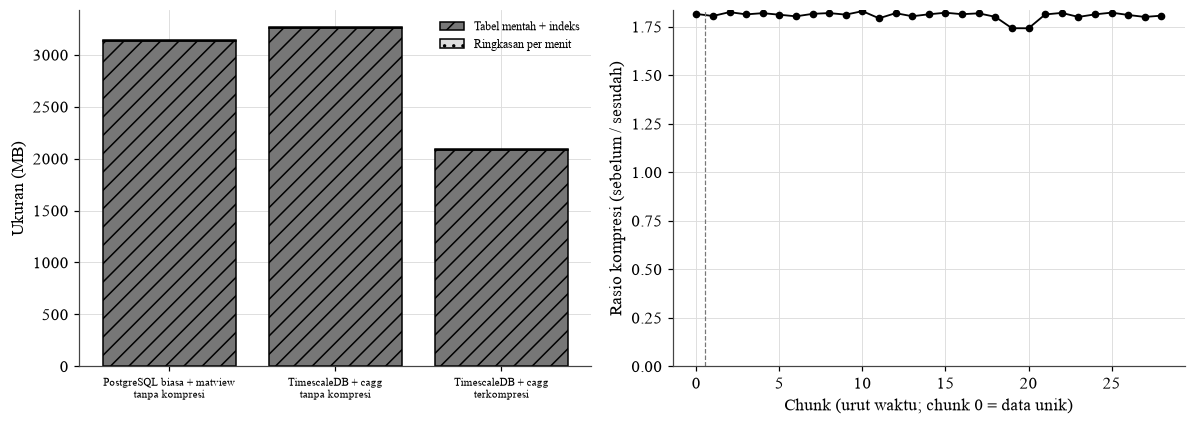

In [13]:
SZ = pd.read_csv(ROOT/"results/02_ukuran.csv"); cs = pd.read_csv(ROOT/"results/02_kompresi_per_chunk.csv")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
lab = [f"{r.konfigurasi}\n{r.fase}" for _, r in SZ.iterrows()]
ax[0].bar(range(3), SZ.tabel_mentah_mb, color="#777", edgecolor="#000", hatch="//", label="Tabel mentah + indeks")
ax[0].bar(range(3), SZ.ringkasan_mb, bottom=SZ.tabel_mentah_mb, color="#ddd", edgecolor="#000", hatch="..", label="Ringkasan per menit")
ax[0].set_xticks(range(3)); ax[0].set_xticklabels(lab, fontsize=7); ax[0].set_ylabel("Ukuran (MB)"); ax[0].legend(frameon=False, fontsize=8)
ax[1].plot(range(len(cs)), cs.rasio, color="#000", marker="o", ms=4, lw=1.2); ax[1].axvline(.5, color="#777", ls="--", lw=.8)
ax[1].set_xlabel("Chunk (urut waktu; chunk 0 = data unik)"); ax[1].set_ylabel("Rasio kompresi (sebelum / sesudah)"); ax[1].set_ylim(0, None)
fig.tight_layout(); fig.savefig(ROOT/"grafik/02_ukuran_kompresi.png"); plt.show()

In [14]:
rf = pd.read_csv(ROOT/"results/02_refresh.csv"); ins = pd.read_csv(ROOT/"results/02_insert_realtime.csv"); bk = pd.read_csv(ROOT/"results/02_bulk_insert.csv")
print("Refresh setelah 1 jam data baru (detik, median 5 ulangan):"); display(rf.drop(columns="rep").median().round(3).to_frame("median_s"))
print("Insert:"); display(ins.round(1)); display(bk.round(1))
Z = pd.read_csv(ROOT/"results/02_query_zoom_raw.csv"); print("Zoom 10 detik:"); display(Z.groupby(["konfigurasi", "kondisi"]).ms.agg(["median", lambda s: s.quantile(.25), lambda s: s.quantile(.75), "max"]).round(2))

Refresh setelah 1 jam data baru (detik, median 5 ulangan):


,median_s
matview_penuh_s,1.888
matview_concurrently_s,1.972
cagg_inkremental_s,0.009


Insert:


,db,1_baris_per_insert_rows_s,1_baris_p99_ms,200_baris_per_perintah_rows_s,200_baris_p99_ms
0,plain,2942.7,0.4,17754.6,13.9
1,ts,2381.8,0.7,14430.2,28.5


,db,baris,detik,baris_per_detik
0,plain,4924800,87.8,56080.7
1,ts,4924800,110.7,44473.4


Zoom 10 detik:


median  <lambda_0>  <lambda_1>   max
konfigurasi            kondisi                                             
PostgreSQL biasa       tanpa kompresi    0.67        0.54        0.81  0.90
TimescaleDB hypertable tanpa kompresi    0.73        0.48        1.02  1.82
                       terkompresi       1.46        1.20        1.71  2.75


## Kesimpulan notebook 02

Dibaca dari tabel dan grafik di atas. Data: pasien 1 selama 30 hari ditambah 9 pasien latar (3 hari), total 4,92 juta baris per database. Docker Desktop di Apple M2, satu ulangan penuh dengan 7 ulangan per query.

**Query riwayat (median, cache hangat, 30 hari).**
- PostgreSQL biasa 1.667 ms, TimescaleDB hypertable 1.345 ms, PostgreSQL + materialized view 52 ms, TimescaleDB + continuous aggregate 36 ms.
- Perbandingan versi 1 (PostgreSQL biasa vs continuous aggregate) memberi selisih 46 kali. Dengan pembanding yang adil (materialized view), selisihnya 32 kali. **Hampir seluruh keuntungan berasal dari ringkasan yang sudah dihitung, bukan dari TimescaleDB itu sendiri.** Continuous aggregate masih lebih cepat dari materialized view, tetapi hanya sekitar 1,4 kali pada 30 hari (36 ms vs 52 ms) dan nyaris sama pada rentang pendek.
- Hypertable mentah hanya sedikit lebih cepat dari tabel biasa (1,2 kali pada 30 hari). Setelah dikompresi, query mentah 30 hari justru lebih cepat (301 ms), kemungkinan karena data yang dibaca lebih sedikit (TODO: verifikasi penyebabnya).

**Query zoom 10 detik (mentah).** PostgreSQL biasa 0,67 ms, hypertable 0,73 ms, hypertable terkompresi 1,46 ms. Semuanya jauh di bawah 16,7 ms. Kompresi menggandakan waktu baca zoom pada data lama, tetapi tidak menjadi masalah.

**Biaya sisi lain**
- **Insert bulk (COPY, dengan indeks):** PostgreSQL 56 ribu baris/detik, TimescaleDB 44 ribu baris/detik (sekitar 21% lebih lambat).
- **Insert real-time:** satu baris per INSERT: 2.943 vs 2.382 baris/detik. 200 baris per perintah: 17.755 vs 14.430 baris/detik, dengan p99 13,9 ms vs 28,5 ms. Kebutuhan sistem 200 baris/detik (200 pasien), jadi kedua konfigurasi punya ruang lebih dari 10 kali lipat. TimescaleDB lebih lambat menulis, bukan lebih cepat.
- **Refresh ringkasan setelah 1 jam data baru** (tabel 30 hari): `REFRESH MATERIALIZED VIEW` sekitar 1,4 sampai 4,1 detik (menghitung ulang seluruh tabel, dan akan membesar seiring tabel), `CONCURRENTLY` sekitar 1,9 sampai 3,0 detik, continuous aggregate inkremental 0,01 sampai 0,03 detik. Pembuatan awal ringkasan justru lebih lambat di continuous aggregate (25,6 detik vs 4,5 detik).
- **Ukuran:** tanpa kompresi PostgreSQL 3.145 MB dan TimescaleDB 3.265 MB (TimescaleDB 4% lebih besar). Setelah mengompresi chunk yang lebih tua dari 1 hari, TimescaleDB 2.091 MB. Rasio per chunk sekitar 1,8 kali, rasio total 1,56 kali. Itu sederhana, karena sinyal EKG ber-entropi tinggi. Ringkasan per menit hanya 8 sampai 10 MB. Waktu kompresi 25 detik.
- **Pengaruh data berulang:** rasio chunk pertama (data unik) 1,82 sama dengan chunk-chunk hasil putar ulang (1,74 sampai 1,83), jadi tidak ada tanda bahwa pengulangan membuat kompresi tampak lebih baik.

**Pembacaan untuk aplikasi.** Kalau tujuannya hanya riwayat cepat, ringkasan per menit sudah cukup, baik lewat materialized view maupun continuous aggregate. Alasan memilih TimescaleDB menjadi lebih lemah dari klaim versi 1: refresh inkremental yang jauh lebih murah (penting jika ringkasan diperbarui tiap menit) dan kompresi 1,6 kali. Harganya: insert 20% sampai 25% lebih lambat dan p99 insert batch dua kali lebih besar. Tabel ringkasan yang diperbarui inkremental di PostgreSQL biasa (pembanding yang lebih kuat dari materialized view) tidak diuji.

**Keterbatasan**
- Satu mesin, satu kontainer Docker Desktop (VM Linux di macOS, overhead I/O), cache hangat saja. Cache dingin, beban baca dan tulis bersamaan, dan banyak klien tidak diuji.
- Satu pasien dengan 30 hari data penuh, data MIT-BIH diputar ulang. Skala pasien (puluhan sampai ratusan pasien dengan 30 hari data) tidak diuji, padahal itu yang paling mempengaruhi ukuran dan biaya refresh.
- Insert diukur dengan satu koneksi. Pada penulisan paralel dari banyak koneksi, hasil bisa berbeda.
- Tag image `latest-pg16` bergerak. Versi sebenarnya ada di `results/env_02.json`.
